<a href="https://colab.research.google.com/github/souvikdey214-code/Krutanic_Weekly-Project-Task/blob/main/07_Reel_Match.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

from surprise import Dataset, Reader, SVD
from surprise.model_selection import GridSearchCV, cross_validate

In [ ]:
import os
import zipfile

zip_path = "ml-latest-small.zip"
dataset_path = "ml-latest-small"
if not os.path.exists(dataset_path):
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(".")

print("Dataset path:", dataset_path)
print("Files available:", os.listdir(dataset_path))

Dataset path: ml-latest-small
Files available: ['links.csv', 'movies.csv', 'ratings.csv', 'README.txt', 'tags.csv']


In [ ]:
import pandas as pd
import os

movies_path = os.path.join(dataset_path, "movies.csv")
ratings_path = os.path.join(dataset_path, "ratings.csv")

movies = pd.read_csv(movies_path)
ratings = pd.read_csv(ratings_path)

print("Movies dataset loaded successfully!")
print("Ratings dataset loaded successfully!")

print("Number of movies:", len(movies))
print("Number of ratings:", len(ratings))

Movies dataset loaded successfully!
Ratings dataset loaded successfully!
Number of movies: 9742
Number of ratings: 100836


In [ ]:
print("Number of users:", ratings['userId'].nunique())
print("Number of movies:", movies['movieId'].nunique())
print("Number of ratings:", len(ratings))

print("\nRating range:")
print(ratings['rating'].min(), "to", ratings['rating'].max())

Number of users: 610
Number of movies: 9742
Number of ratings: 100836

Rating range:
0.5 to 5.0


In [ ]:
data = ratings.merge(
    movies,
    on="movieId",
    how="left"
)

print("Merged dataset shape:", data.shape)

Merged dataset shape: (100836, 6)


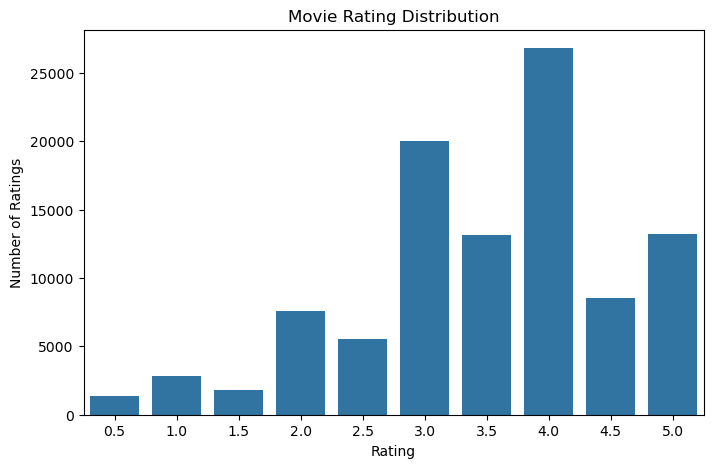

In [ ]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=ratings,
    x="rating"
)

plt.title("Movie Rating Distribution")
plt.xlabel("Rating")
plt.ylabel("Number of Ratings")

plt.show()

In [ ]:
movie_stats = data.groupby("title").agg(
    rating_count=("rating", "count"),
    average_rating=("rating", "mean")
).sort_values(
    "rating_count",
    ascending=False
)

movie_stats.head(10)

,rating_count,average_rating
title,,
Forrest Gump (1994),329,4.164134
"Shawshank Redemption, The (1994)",317,4.429022
Pulp Fiction (1994),307,4.197068
"Silence of the Lambs, The (1991)",279,4.161290
"Matrix, The (1999)",278,4.192446
Star Wars: Episode IV - A New Hope (1977),251,4.231076
Jurassic Park (1993),238,3.750000
Braveheart (1995),237,4.031646
Terminator 2: Judgment Day (1991),224,3.970982


In [ ]:
user_item_matrix = ratings.pivot_table(
    index="userId",
    columns="movieId",
    values="rating"
)

print("Matrix shape:", user_item_matrix.shape)

Matrix shape: (610, 9724)


In [ ]:
total_elements = user_item_matrix.size
missing_elements = user_item_matrix.isna().sum().sum()

sparsity = (missing_elements / total_elements) * 100

print(f"Sparsity: {sparsity:.2f}%")

Sparsity: 98.30%


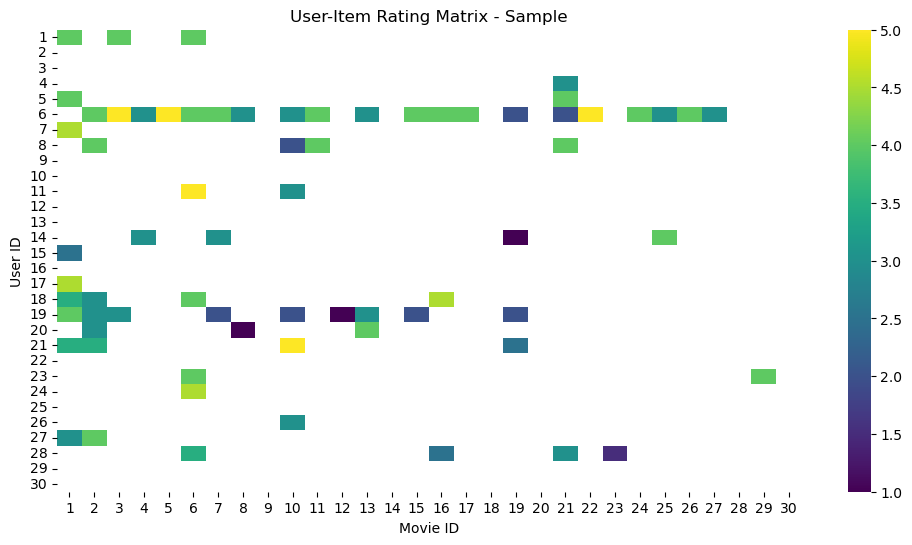

In [ ]:
plt.figure(figsize=(12,6))

sns.heatmap(
    user_item_matrix.iloc[:30, :30],
    cmap="viridis",
    cbar=True
)

plt.title("User-Item Rating Matrix - Sample")
plt.xlabel("Movie ID")
plt.ylabel("User ID")

plt.show()

In [ ]:
content_data = movies.copy()

content_data["genres"] = content_data["genres"].fillna("")

content_data.head()

,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


In [ ]:
tfidf = TfidfVectorizer(
    tokenizer=lambda x: x.split("|"),
    token_pattern=None
)

tfidf_matrix = tfidf.fit_transform(
    content_data["genres"]
)

print("TF-IDF matrix shape:", tfidf_matrix.shape)

TF-IDF matrix shape: (9742, 20)


In [ ]:
content_similarity = cosine_similarity(
    tfidf_matrix
)

print(
    "Similarity matrix shape:",
    content_similarity.shape
)

Similarity matrix shape: (9742, 9742)


In [ ]:
movie_indices = pd.Series(
    content_data.index,
    index=content_data["title"]
).drop_duplicates()

In [ ]:
def recommend_similar(movie_title, n=10):

    if movie_title not in movie_indices:
        return pd.DataFrame(
            {"Message": ["Movie not found in dataset"]}
        )

    idx = movie_indices[movie_title]

    similarity_scores = list(
        enumerate(content_similarity[idx])
    )

    similarity_scores = sorted(
        similarity_scores,
        key=lambda x: x[1],
        reverse=True
    )

    similarity_scores = similarity_scores[1:n+1]

    movie_indices_list = [
        i[0] for i in similarity_scores
    ]

    scores = [
        i[1] for i in similarity_scores
    ]

    result = content_data.iloc[
        movie_indices_list
    ][["movieId", "title", "genres"]].copy()

    result["similarity"] = scores

    return result.reset_index(drop=True)

In [ ]:
movie_name = movies["title"].iloc[0]

print("Selected movie:", movie_name)

recommend_similar(
    movie_name,
    10
)

Selected movie: Toy Story (1995)


,movieId,title,genres,similarity
0,2294,Antz (1998),Adventure|Animation|Children|Comedy|Fantasy,1.0
1,3114,Toy Story 2 (1999),Adventure|Animation|Children|Comedy|Fantasy,1.0
2,3754,"Adventures of Rocky and Bullwinkle, The (2000)",Adventure|Animation|Children|Comedy|Fantasy,1.0
3,4016,"Emperor's New Groove, The (2000)",Adventure|Animation|Children|Comedy|Fantasy,1.0
4,4886,"Monsters, Inc. (2001)",Adventure|Animation|Children|Comedy|Fantasy,1.0
5,45074,"Wild, The (2006)",Adventure|Animation|Children|Comedy|Fantasy,1.0
6,53121,Shrek the Third (2007),Adventure|Animation|Children|Comedy|Fantasy,1.0
7,65577,"Tale of Despereaux, The (2008)",Adventure|Animation|Children|Comedy|Fantasy,1.0
8,91355,Asterix and the Vikings (Astérix et les Viking...,Adventure|Animation|Children|Comedy|Fantasy,1.0
9,103755,Turbo (2013),Adventure|Animation|Children|Comedy|Fantasy,1.0


In [ ]:
user_item_filled = user_item_matrix.fillna(0)

print(user_item_filled.shape)

(610, 9724)


In [ ]:
user_similarity = cosine_similarity(
    user_item_filled
)

user_similarity_df = pd.DataFrame(
    user_similarity,
    index=user_item_filled.index,
    columns=user_item_filled.index
)

print(user_similarity_df.shape)

(610, 610)


In [ ]:
def collaborative_recommend(user_id, n=10):

    if user_id not in user_item_matrix.index:
        return pd.DataFrame(
            {"Message": ["User ID not found"]}
        )

    # Similar users
    similarities = user_similarity_df[user_id].drop(
        user_id
    )

    top_users = similarities.sort_values(
        ascending=False
    ).head(5)

    # Movies rated by similar users
    candidate_movies = []

    for similar_user, similarity_score in top_users.items():

        user_ratings = user_item_matrix.loc[
            similar_user
        ].dropna()

        high_rated = user_ratings[
            user_ratings >= 4
        ]

        for movie_id, rating in high_rated.items():

            candidate_movies.append(
                (
                    movie_id,
                    rating,
                    similarity_score
                )
            )

    if len(candidate_movies) == 0:
        return pd.DataFrame(
            {"Message": ["No recommendations available"]}
        )

    candidate_df = pd.DataFrame(
        candidate_movies,
        columns=[
            "movieId",
            "rating",
            "user_similarity"
        ]
    )

    # Weighted score
    candidate_df["weighted_score"] = (
        candidate_df["rating"] *
        candidate_df["user_similarity"]
    )

    recommendations = (
        candidate_df
        .groupby("movieId")
        .agg(
            score=("weighted_score", "sum"),
            rating=("rating", "mean")
        )
        .sort_values(
            "score",
            ascending=False
        )
        .head(n)
        .reset_index()
    )

    recommendations = recommendations.merge(
        movies,
        on="movieId",
        how="left"
    )

    return recommendations[
        ["movieId", "title", "genres", "score", "rating"]
    ]

In [ ]:
user_id = int(ratings["userId"].iloc[0])

print("User ID:", user_id)

collaborative_recommend(
    user_id,
    10
)

User ID: 1


,movieId,title,genres,score,rating
0,1200,Aliens (1986),Action|Adventure|Horror|Sci-Fi,8.324253,4.800
1,2571,"Matrix, The (1999)",Action|Sci-Fi|Thriller,8.324160,4.800
2,1198,Raiders of the Lost Ark (Indiana Jones and the...,Action|Adventure,8.324160,4.800
3,2028,Saving Private Ryan (1998),Action|Drama|War,8.144516,4.700
4,50,"Usual Suspects, The (1995)",Crime|Mystery|Thriller,7.799389,4.500
5,1240,"Terminator, The (1984)",Action|Sci-Fi|Thriller,7.454355,4.300
6,541,Blade Runner (1982),Action|Sci-Fi|Thriller,6.943652,5.000
7,1036,Die Hard (1988),Action|Crime|Thriller,6.935430,4.000
8,858,"Godfather, The (1972)",Crime|Drama,6.882249,5.000
9,296,Pulp Fiction (1994),Comedy|Crime|Drama|Thriller,6.776753,4.875


In [ ]:
reader = Reader(
    rating_scale=(
        ratings["rating"].min(),
        ratings["rating"].max()
    )
)

surprise_data = Dataset.load_from_df(
    ratings[
        ["userId", "movieId", "rating"]
    ],
    reader
)

In [ ]:
from surprise.model_selection import train_test_split

# Split the Surprise dataset into training and testing sets
trainset, testset = train_test_split(
    surprise_data,
    test_size=0.20,
    random_state=42
)

print("Training ratings:", trainset.n_ratings)
print("Test ratings:", len(testset))

Training ratings: 80668
Test ratings: 20168


In [ ]:
svd_model = SVD(
    n_factors=100,
    random_state=42
)

svd_model.fit(trainset)

predictions = svd_model.test(testset)

rmse = np.sqrt(
    np.mean([
        (pred.r_ui - pred.est) ** 2
        for pred in predictions
    ])
)

print(f"SVD RMSE: {rmse:.4f}")

SVD RMSE: 0.8807


In [ ]:
param_grid = {
    "n_factors": [50, 100, 150],
    "n_epochs": [20, 30],
    "lr_all": [0.005, 0.01],
    "reg_all": [0.02, 0.05]
}

grid_search = GridSearchCV(
    SVD,
    param_grid,
    measures=["rmse"],
    cv=3,
    n_jobs=-1
)

grid_search.fit(surprise_data)

print(
    "Best RMSE:",
    grid_search.best_score["rmse"]
)

print(
    "Best Parameters:",
    grid_search.best_params["rmse"]
)

Best RMSE: 0.8654450206492332
Best Parameters: {'n_factors': 150, 'n_epochs': 30, 'lr_all': 0.01, 'reg_all': 0.05}


In [ ]:
best_params = grid_search.best_params["rmse"]

best_svd = SVD(
    **best_params,
    random_state=42
)

best_svd.fit(trainset)

print("Best SVD model trained successfully!")

Best SVD model trained successfully!


In [ ]:
def svd_recommend(user_id, n=10):

    if user_id not in ratings["userId"].values:
        return pd.DataFrame(
            {"Message": ["User ID not found"]}
        )

    rated_movies = set(
        ratings[
            ratings["userId"] == user_id
        ]["movieId"]
    )

    all_movies = movies["movieId"].unique()

    unrated_movies = [
        movie_id
        for movie_id in all_movies
        if movie_id not in rated_movies
    ]

    predictions = []

    for movie_id in unrated_movies:

        prediction = best_svd.predict(
            user_id,
            movie_id
        )

        predictions.append(
            (
                movie_id,
                prediction.est
            )
        )

    predictions_df = pd.DataFrame(
        predictions,
        columns=[
            "movieId",
            "predicted_rating"
        ]
    )

    predictions_df = predictions_df.sort_values(
        "predicted_rating",
        ascending=False
    ).head(n)

    predictions_df = predictions_df.merge(
        movies,
        on="movieId",
        how="left"
    )

    return predictions_df[
        [
            "movieId",
            "title",
            "genres",
            "predicted_rating"
        ]
    ]

In [ ]:
svd_recommend(
    user_id,
    10
)

,movieId,title,genres,predicted_rating
0,7706,Animal Crackers (1930),Comedy|Musical,5.0
1,3347,Never Cry Wolf (1983),Adventure|Drama,5.0
2,170705,Band of Brothers (2001),Action|Drama|War,5.0
3,98491,Paperman (2012),Animation|Comedy|Romance,5.0
4,1221,"Godfather: Part II, The (1974)",Crime|Drama,5.0
5,1223,"Grand Day Out with Wallace and Gromit, A (1989)",Adventure|Animation|Children|Comedy|Sci-Fi,5.0
6,2788,Monty Python's And Now for Something Completel...,Comedy,5.0
7,914,My Fair Lady (1964),Comedy|Drama|Musical|Romance,5.0
8,3083,All About My Mother (Todo sobre mi madre) (1999),Drama,5.0
9,3451,Guess Who's Coming to Dinner (1967),Drama,5.0


In [ ]:
def hybrid_recommend(user_id, movie_title, n=10):

    # -----------------------------
    # 1. Validate User
    # -----------------------------
    if user_id not in ratings["userId"].values:
        return pd.DataFrame({
            "Message": [f"User ID {user_id} not found"]
        })

    # -----------------------------
    # 2. Clean input movie title
    # -----------------------------
    movie_title_clean = str(movie_title).strip()

    # Find matching movie
    movie_match = movies[
        movies["title"]
        .astype(str)
        .str.strip()
        .str.lower()
        == movie_title_clean.lower()
    ]

    if movie_match.empty:

        # Try partial matching
        partial_match = movies[
            movies["title"]
            .astype(str)
            .str.lower()
            .str.contains(
                movie_title_clean.lower(),
                na=False
            )
        ]

        if partial_match.empty:
            return pd.DataFrame({
                "Message": [
                    f"Movie '{movie_title}' not found"
                ]
            })

        movie_match = partial_match.iloc[[0]]

    # Get movie index
    target_movie_id = movie_match.iloc[0]["movieId"]

    # Find index in movies dataframe
    target_idx = movie_match.index[0]

    # -----------------------------
    # 3. Content similarity
    # -----------------------------
    content_score_array = content_similarity[target_idx]

    # -----------------------------
    # 4. Movies already rated
    # -----------------------------
    rated_movies = set(
        ratings.loc[
            ratings["userId"] == user_id,
            "movieId"
        ]
    )

    results = []

    # -----------------------------
    # 5. Generate predictions
    # -----------------------------
    for idx, row in movies.iterrows():

        movie_id = row["movieId"]

        # Don't recommend already-rated movies
        if movie_id in rated_movies:
            continue

        # SVD prediction
        svd_prediction = best_svd.predict(
            user_id,
            movie_id
        ).est

        # Content similarity
        content_score = float(
            content_score_array[idx]
        )

        results.append({
            "movieId": movie_id,
            "svd_score": svd_prediction,
            "content_score": content_score
        })

    # -----------------------------
    # 6. Convert to DataFrame
    # -----------------------------
    result_df = pd.DataFrame(results)

    if result_df.empty:
        return pd.DataFrame({
            "Message": [
                "No recommendations available."
            ]
        })

    # -----------------------------
    # 7. Normalize SVD scores
    # -----------------------------
    min_score = result_df["svd_score"].min()
    max_score = result_df["svd_score"].max()

    if max_score > min_score:

        result_df["svd_normalized"] = (
            result_df["svd_score"] - min_score
        ) / (
            max_score - min_score
        )

    else:

        result_df["svd_normalized"] = 0.5

    # -----------------------------
    # 8. Hybrid score
    # -----------------------------
    result_df["hybrid_score"] = (
        0.70 * result_df["svd_normalized"]
        +
        0.30 * result_df["content_score"]
    )

    # -----------------------------
    # 9. Sort recommendations
    # -----------------------------
    result_df = result_df.sort_values(
        by="hybrid_score",
        ascending=False
    )

    result_df = result_df.head(n)

    # -----------------------------
    # 10. Add movie information
    # -----------------------------
    result_df = result_df.merge(
        movies[
            ["movieId", "title", "genres"]
        ],
        on="movieId",
        how="left"
    )

    return result_df[
        [
            "movieId",
            "title",
            "genres",
            "svd_score",
            "content_score",
            "hybrid_score"
        ]
    ].reset_index(drop=True)

In [ ]:
# Check whether Shrek exists

shrek_movies = movies[
    movies["title"]
    .astype(str)
    .str.contains("Shrek", case=False, na=False)
]

display(shrek_movies)

,movieId,title,genres
3194,4306,Shrek (2001),Adventure|Animation|Children|Comedy|Fantasy|Ro...
5160,8360,Shrek 2 (2004),Adventure|Animation|Children|Comedy|Musical|Ro...
6486,53121,Shrek the Third (2007),Adventure|Animation|Children|Comedy|Fantasy
6915,64249,Shrek the Halls (2007),Adventure|Animation|Comedy|Fantasy
7360,78637,Shrek Forever After (a.k.a. Shrek: The Final C...,Adventure|Animation|Children|Comedy|Fantasy|IMAX


In [ ]:
# Cell 31 - User Input

user_id = int(
    input("Enter User ID: ")
)

movie_title = input(
    "Enter Movie Title: "
)

print("\n" + "=" * 70)
print("MOVIE RECOMMENDATIONS")
print("=" * 70)

print("User ID:", user_id)
print("Reference Movie:", movie_title)

recommendations = hybrid_recommend(
    user_id,
    movie_title,
    10
)

print("\nRecommended Movies:\n")

display(recommendations)

Enter User ID:  7
Enter Movie Title:  My Fair Lady



MOVIE RECOMMENDATIONS
User ID: 7
Reference Movie: My Fair Lady

Recommended Movies:



,movieId,title,genres,svd_score,content_score,hybrid_score
0,912,Casablanca (1942),Drama|Romance,4.656739,0.571969,0.852888
1,914,My Fair Lady (1964),Comedy|Drama|Musical|Romance,4.003445,1.000000,0.848056
2,899,Singin' in the Rain (1952),Comedy|Musical|Romance,4.002916,0.951036,0.833259
3,1236,Trust (1990),Comedy|Drama|Romance,4.386367,0.662684,0.824960
4,54190,Across the Universe (2007),Drama|Fantasy|Musical|Romance,4.124417,0.793332,0.810728
5,898,"Philadelphia Story, The (1940)",Comedy|Drama|Romance,4.313246,0.662684,0.810046
6,4642,Hedwig and the Angry Inch (2000),Comedy|Drama|Musical,3.930831,0.876573,0.796218
7,6732,"Hello, Dolly! (1969)",Comedy|Musical|Romance,3.805191,0.951036,0.792933
8,1247,"Graduate, The (1967)",Comedy|Drama|Romance,4.228438,0.662684,0.792749
9,7121,Adam's Rib (1949),Comedy|Romance,4.319229,0.586191,0.788319


In [ ]:
def get_relevant_movies(
    user_id,
    threshold=4
):

    user_ratings = ratings[
        ratings["userId"] == user_id
    ]

    relevant = set(
        user_ratings[
            user_ratings["rating"] >= threshold
        ]["movieId"]
    )

    return relevant

In [ ]:
def precision_recall_at_k(
    recommended,
    relevant,
    k=10
):

    recommended = recommended[:k]

    recommended_set = set(
        recommended
    )

    relevant_set = set(
        relevant
    )

    if len(recommended_set) == 0:
        return 0, 0

    hits = len(
        recommended_set &
        relevant_set
    )

    precision = hits / len(
        recommended_set
    )

    recall = (
        hits / len(relevant_set)
        if len(relevant_set) > 0
        else 0
    )

    return precision, recall

In [ ]:
def evaluate_svd(
    user_id,
    k=10
):

    recommendations = svd_recommend(
        user_id,
        k
    )

    recommended_movies = (
        recommendations["movieId"]
        .tolist()
    )

    relevant_movies = get_relevant_movies(
        user_id
    )

    precision, recall = (
        precision_recall_at_k(
            recommended_movies,
            relevant_movies,
            k
        )
    )

    return precision, recall

In [ ]:
# Cell 35 - Improved Precision@10 and Recall@10 Evaluation

from collections import defaultdict

K = 10
relevant_threshold = 4.0

# Store predictions for each user
user_predictions = defaultdict(list)

# Predict ratings for the test set
for user_id, movie_id, actual_rating in testset:

    predicted_rating = best_svd.predict(
        user_id,
        movie_id
    ).est

    user_predictions[user_id].append(
        (movie_id, actual_rating, predicted_rating)
    )

precision_scores = []
recall_scores = []

# Evaluate each user
for user_id, predictions in user_predictions.items():

    # Sort movies according to predicted rating
    predictions = sorted(
        predictions,
        key=lambda x: x[2],
        reverse=True
    )

    # Top K recommendations
    top_k = predictions[:K]

    # Movies actually relevant in test data
    relevant_movies = {
        movie_id
        for movie_id, actual_rating, predicted_rating
        in predictions
        if actual_rating >= relevant_threshold
    }

    # Movies recommended in Top K
    recommended_movies = {
        movie_id
        for movie_id, actual_rating, predicted_rating
        in top_k
    }

    # Number of correct recommendations
    hits = len(
        recommended_movies &
        relevant_movies
    )

    # Precision@K
    precision = hits / K

    # Recall@K
    if len(relevant_movies) > 0:
        recall = hits / len(relevant_movies)
    else:
        recall = 0

    precision_scores.append(precision)
    recall_scores.append(recall)

# Average across users
precision_at_10 = np.mean(precision_scores)
recall_at_10 = np.mean(recall_scores)

print("=" * 50)
print("SVD MODEL EVALUATION")
print("=" * 50)

print(
    f"Precision@10: {precision_at_10 * 100:.2f}%"
)

print(
    f"Recall@10: {recall_at_10 * 100:.2f}%"
)

print("=" * 50)

SVD MODEL EVALUATION
Precision@10: 56.72%
Recall@10: 66.52%
